# Part 1 – Reinforcement Learning Control of the Robot (Q-learning)

1. **Setup**: environment, settings and the Q-learning functions
2. **Baseline**: one Q-table trained from random starts
3. **Per-configuration Q-learning**: one training run per configuration, as the specification asks, stored in a dictionary
4. **Evaluation**: how well the controllers work on training and unseen starts
5. **Dataset for Part 2**: the 404-row file `(taxi location, passenger location, destination) -> optimum action`

## 1. Setup

In [67]:
import time
import random
from collections import deque

import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Settings

In [68]:
# q-learning update
alpha = 0.9 # learning rate
gamma = 0.95 # discount factor

# exploration (epsilon-greedy)
epsilon = 1.0       
min_epsilon = 0.01   

# baseline
num_episodes = 10000     
epsilon_decay = 0.9995   
max_steps = 200          

# per-configuration runs
episodes_per_config = 300  
config_epsilon_decay = min_epsilon ** (1 / (0.8 * episodes_per_config))

seed = 0    

In [69]:
# init the environment
env = gym.make("Taxi-v4")
u = env.unwrapped  

# action types
actions = ["south(0)", "north(1)", "east(2)", "west(3)", "pickup(4)", "dropoff(5)"]

print("States :", env.observation_space.n)
print("Actions:", env.action_space.n)

States : 500
Actions: 6


In [70]:
# init q table (500 states x 6 actions) and display it with its initial 0 values
q_table = np.zeros((env.observation_space.n, env.action_space.n))

q_df = pd.DataFrame(q_table, columns=actions)
q_df.index.name = "state"
q_df

,south(0),north(1),east(2),west(3),pickup(4),dropoff(5)
state,,,,,,
0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...
495,0.0,0.0,0.0,0.0,0.0,0.0
496,0.0,0.0,0.0,0.0,0.0,0.0
497,0.0,0.0,0.0,0.0,0.0,0.0


### The Q-learning update, one piece at a time

- **Observed Q-value (TD target)**
- **TD error**
- **Update rule**

In [71]:
# helping functions
def get_observed_q_value(reward, gamma, result_state_highest_q_value_of_action, terminated):
    if terminated:                      
        return reward
    return reward + (gamma * result_state_highest_q_value_of_action)

def get_td_error(observed_q_value, existing_q_value):
    return observed_q_value - existing_q_value

def update_rule_of_cell(existing_q_value, alpha, td_error):
    return existing_q_value + (alpha * td_error)

def choose_action_epsilon_greedy(Q, state, epsilon):
    if random.uniform(0, 1) < epsilon:
        return env.action_space.sample()
    return choose_best_action(Q, state)

def choose_best_action(Q, state):
    return int(np.argmax(Q[state]))

In [72]:
# update one cell at a time
def update_one_cell(Q, state, action, reward, next_state, terminated, alpha, gamma):
    result_state_highest_q_value_of_action = np.max(Q[next_state])
    existing_q_value = Q[state, action]

    observed_q_value = get_observed_q_value(reward, gamma, result_state_highest_q_value_of_action, terminated)
    td_error = get_td_error(observed_q_value, existing_q_value)

    Q[state, action] = update_rule_of_cell(existing_q_value, alpha, td_error)

def run_one_episode(Q, epsilon, alpha, gamma, max_steps, reset_seed=None, start_state=None):
    state, _ = env.reset(seed=reset_seed)

    if start_state is not None:
        u.s = start_state
        state = start_state

    total_reward = 0

    for step in range(max_steps):
        action = choose_action_epsilon_greedy(Q, state, epsilon)
        next_state, reward, terminated, truncated, info = env.step(action)

        update_one_cell(Q, state, action, reward, next_state, terminated, alpha, gamma)

        total_reward += reward
        state = next_state

        if terminated or truncated:
            break

    return total_reward

In [73]:
# iterate over many episodes and learn
def train_q_learning(num_episodes=10000, alpha=0.9, gamma=0.95,
                     epsilon=1.0, epsilon_decay=0.9995, min_epsilon=0.01, max_steps=100,
                     seed=0, start_state=None):
    random.seed(seed)              
    env.action_space.seed(seed)    

    Q = np.zeros((env.observation_space.n, env.action_space.n))
    rewards_per_episode = []

    for episode in range(num_episodes):
        reset_seed = seed if episode == 0 else None
        total_reward = run_one_episode(Q, epsilon, alpha, gamma, max_steps, reset_seed, start_state)
        rewards_per_episode.append(total_reward)
        epsilon = max(min_epsilon, epsilon * epsilon_decay)

    return Q, rewards_per_episode

### Reachable states

The 500 states include 96 that can never happen (the passenger already at the destination while the taxi is elsewhere). This leaves the 404 reachable states out of 500:

- **300** with the passenger waiting at a stop and a different destination
- **100** with the passenger in the taxi
- **4** right after a successful drop-off (the episode has already ended)

In [74]:
# extract only the 404 reachable states
def get_reachable_states(env):
    u = env.unwrapped
    reachable_states = []

    for s in range(env.observation_space.n):
        taxi_row, taxi_col, pass_idx, dest_idx = u.decode(s)

        if pass_idx < 4 and pass_idx != dest_idx:        # passenger waiting at a stop
            reachable_states.append(s)
        elif pass_idx == 4:                               # passenger in the taxi
            reachable_states.append(s)
        elif (taxi_row, taxi_col) == u.locs[dest_idx]:    # just dropped off at the destination
            reachable_states.append(s)
        # anything else: passenger at the destination but taxi elsewhere is considered impossible

    return reachable_states


reachable_states = get_reachable_states(env)
skipped_states = [s for s in range(env.observation_space.n) if s not in reachable_states]

# the 4 states right after a drop-off: passenger and taxi both at the destination
finished_states = [s for s in reachable_states if u.decode(s)[2] == u.decode(s)[3]]

# every other reachable state is a configuration the taxi can actually be in and move from
configurations = [s for s in reachable_states if s not in finished_states]
start_states = [s for s in configurations if u.decode(s)[2] < 4]          # passenger waiting at a stop
in_taxi_states = [s for s in configurations if u.decode(s)[2] == 4]       # passenger inside the taxi

print("Reachable states :", len(reachable_states))
print("Skipped states   :", len(skipped_states))
print("Finished states  :", finished_states)
print("Configurations   :", len(configurations),
      f"({len(start_states)} passenger waiting + {len(in_taxi_states)} passenger in taxi)")

Reachable states : 404
Skipped states   : 96
Finished states  : [0, 85, 410, 475]
Configurations   : 400 (300 passenger waiting + 100 passenger in taxi)


## 2. Baseline: one Q-table trained from random starts

In [75]:
start_time = time.time()
Q, rewards = train_q_learning(num_episodes=num_episodes, alpha=alpha, gamma=gamma,
                              epsilon=epsilon, epsilon_decay=epsilon_decay,
                              min_epsilon=min_epsilon, max_steps=max_steps, seed=seed)
baseline_time = time.time() - start_time

print(f"Training time: {baseline_time:.1f} s")
print("Non-zero cells:", np.count_nonzero(Q), "/", Q.size,
      "(400 reachable non-finished states x 6 actions = 2400)")
print("Average reward, first 100 episodes:", np.mean(rewards[:100]))
print("Average reward, last 100 episodes :", np.mean(rewards[-100:]))

Training time: 8.5 s
Non-zero cells: 2400 / 3000 (400 reachable non-finished states x 6 actions = 2400)
Average reward, first 100 episodes: -762.88
Average reward, last 100 episodes : 6.97


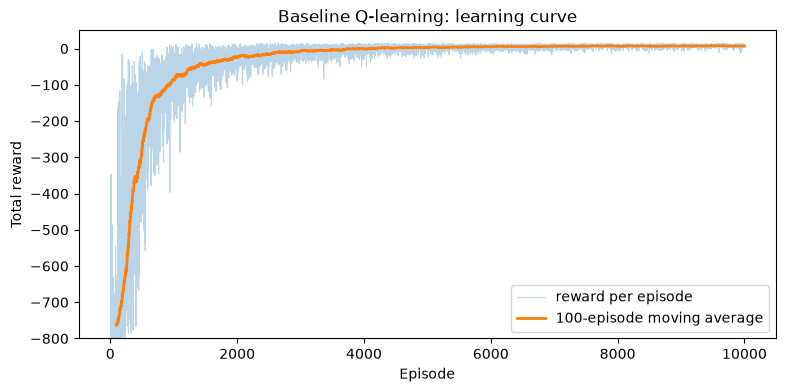

In [76]:
# learning curve: total reward per episode, with a 100-episode moving average
moving_average = pd.Series(rewards).rolling(100).mean()

plt.figure(figsize=(9, 4))
plt.plot(rewards, alpha=0.3, linewidth=0.8, label="reward per episode")
plt.plot(moving_average, linewidth=2, label="100-episode moving average")
plt.ylim(-800, 50)
plt.xlabel("Episode")
plt.ylabel("Total reward")
plt.title("Baseline Q-learning: learning curve")
plt.legend()
plt.show()

In [77]:
Q_df = pd.DataFrame(Q, columns=actions)
Q_df.index.name = "state"
Q_df

,south(0),north(1),east(2),west(3),pickup(4),dropoff(5)
state,,,,,,
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,2.752004,3.949478,2.752004,3.949478,5.209976,-5.050522
2,7.933492,9.403676,7.933492,9.403676,10.951237,0.403676
3,3.949478,5.209976,3.949478,5.209976,6.536817,-3.790024
4,-9.315030,-9.493719,-3.275187,-5.027954,-18.542130,-14.027352
...,...,...,...,...,...,...
495,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
496,5.199474,6.536817,5.209936,6.536817,-3.790024,-3.790024
497,10.951237,12.580250,10.951237,9.403676,1.951237,1.951237


In [78]:
# prepare the reachable q_table
def build_reachable_q_table(Q, env):
    u = env.unwrapped
    rows = []

    for s in get_reachable_states(env):
        taxi_row, taxi_col, pass_idx, dest_idx = u.decode(s)
        rows.append([s, taxi_row, taxi_col, pass_idx, dest_idx] + list(Q[s]))

    columns = ["state", "taxi_row", "taxi_col", "pass_idx", "dest_idx"] + actions
    return pd.DataFrame(rows, columns=columns).set_index("state")


reachable_Q_df = build_reachable_q_table(Q, env)

print("Full Q-table     :", Q_df.shape)
print("Reachable Q-table:", reachable_Q_df.shape)
reachable_Q_df

Full Q-table     : (500, 6)
Reachable Q-table: (404, 10)


,taxi_row,taxi_col,pass_idx,dest_idx,south(0),north(1),east(2),west(3),pickup(4),dropoff(5)
state,,,,,,,,,,
0,0,0,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,0,0,0,1,2.752004,3.949478,2.752004,3.949478,5.209976,-5.050522
2,0,0,0,2,7.933492,9.403676,7.933492,9.403676,10.951237,0.403676
3,0,0,0,3,3.949478,5.209976,3.949478,5.209976,6.536817,-3.790024
4,0,0,1,0,-9.315030,-9.493719,-3.275187,-5.027954,-18.542130,-14.027352
...,...,...,...,...,...,...,...,...,...,...
494,4,4,3,2,3.949478,2.752004,3.949478,5.209976,-5.050522,-5.050522
496,4,4,4,0,5.199474,6.536817,5.209936,6.536817,-3.790024,-3.790024
497,4,4,4,1,10.951237,12.580250,10.951237,9.403676,1.951237,1.951237


## 3. Per-configuration Q-learning

In [79]:
q_tables = {}          # key: (taxi_row, taxi_col, pass_idx, dest_idx) -> that configuration's 500 x 6 Q-table
config_rewards = {}    # reward per episode for each configuration

start_time = time.time()
for s in configurations:
    config = tuple(int(v) for v in u.decode(s))
    q_tables[config], config_rewards[config] = train_q_learning(
        num_episodes=episodes_per_config, alpha=alpha, gamma=gamma,
        epsilon=epsilon, epsilon_decay=config_epsilon_decay,
        min_epsilon=min_epsilon, max_steps=max_steps,
        seed=s,                 # a different but repeatable random sequence for each configuration
        start_state=s)
per_config_time = time.time() - start_time

print("Configurations trained:", len(q_tables))
print(f"Episodes per configuration: {episodes_per_config} (epsilon decay {config_epsilon_decay:.4f})")
print(f"Total episodes: {len(q_tables) * episodes_per_config}")
print(f"Training time: {per_config_time:.1f} s")

Configurations trained: 400
Episodes per configuration: 300 (epsilon decay 0.9810)
Total episodes: 120000
Training time: 170.2 s


In [80]:
# example: the learned Q-values for one configuration, at its own start state
example_config = (2, 2, 0, 3)                        # taxi at (2, 2), passenger at Red, destination Blue
example_state = u.encode(*example_config)
print("Configuration", example_config, "-> state", example_state)
print(pd.DataFrame([q_tables[example_config][example_state]], columns=actions).round(2))
print("Best action:", actions[choose_best_action(q_tables[example_config], example_state)])

Configuration (2, 2, 0, 3) -> state 243
   south(0)  north(1)  east(2)  west(3)  pickup(4)  dropoff(5)
0     -0.49     -2.07    -0.49     1.61      -8.47       -8.47
Best action: west(3)


## 4. Evaluation

A controller is tested by letting it drive greedily (always the action with the highest Q-value) and recording:

- whether the passenger is delivered within 200 steps
- the number of steps, compared with the shortest possible route
- illegal pickup/drop-off attempts

The shortest route is found with a breadth-first search over the environment's transition table (`u.P`). I used it only used to check the controllers, never to train them.

In [81]:
# shortest number of actions from a state to a successful drop-off (breadth-first search)
def shortest_path_length(start_state):
    distance = {start_state: 0}
    queue = deque([start_state])
    while queue:
        s = queue.popleft()
        for a in range(6):
            prob, next_state, reward, terminated = u.P[s][a][0]
            if terminated:
                return distance[s] + 1
            if next_state not in distance:
                distance[next_state] = distance[s] + 1
                queue.append(next_state)
    return None

# drive one trip greedily with a q-table from a chosen start state
def run_greedy_episode(Q, start_state, max_steps=200):
    env.reset()
    u.s = start_state
    state = start_state
    total_reward, illegal_moves = 0, 0

    for step in range(1, max_steps + 1):
        action = choose_best_action(Q, state)
        state, reward, terminated, truncated, info = env.step(action)
        total_reward += reward
        if reward == -10:
            illegal_moves += 1
        if terminated:
            return {"delivered": True, "steps": step, "reward": total_reward, "illegal": illegal_moves}

    return {"delivered": False, "steps": max_steps, "reward": total_reward, "illegal": illegal_moves}

shortest = {s: shortest_path_length(s) for s in configurations}

### Training data

- **Per-configuration:** each table is tested from the configuration it was trained on.
- **Baseline:** tested from the 300 passenger-waiting starts, which are the starts `reset()` gives during training.

In [82]:
def summarise(results, name):
    df = pd.DataFrame(results)
    delivered = df[df["delivered"]]
    return {"test": name,
            "trips": len(df),
            "delivered": int(df["delivered"].sum()),
            "shortest route": int((delivered["steps"] == delivered["shortest"]).sum()),
            "avg extra steps": round((delivered["steps"] - delivered["shortest"]).mean(), 2) if len(delivered) else None,
            "avg reward": round(df["reward"].mean(), 2),
            "illegal moves": int(df["illegal"].sum())}

evaluation_rows = []

# per-configuration tables, each from its own start
results = []
for s in configurations:
    config = tuple(int(v) for v in u.decode(s))
    r = run_greedy_episode(q_tables[config], s)
    results.append({**r, "shortest": shortest[s]})
evaluation_rows.append(summarise(results, "Per-config: own start (training)"))

# baseline table from the 300 starts it trained on
results = [{**run_greedy_episode(Q, s), "shortest": shortest[s]} for s in start_states]
evaluation_rows.append(summarise(results, "Baseline: 300 reset starts (training)"))

pd.DataFrame(evaluation_rows)

,test,trips,delivered,shortest route,avg extra steps,avg reward,illegal moves
0,Per-config: own start (training),400,400,400,0.0,9.80,0
1,Baseline: 300 reset starts (training),300,300,300,0.0,7.93,0


### Unseen data: starts the controller never trained from

- **Per-configuration:** each table is tested from a *different*, randomly chosen configuration.
- **Baseline:** tested from the 100 passenger-in-taxi configurations. `reset()` never starts an episode there, so these were never used as starts in training (the taxi only passed through them mid-trip).

In [83]:
rng = np.random.default_rng(seed)

# per-configuration tables, each from a different configuration
results = []
for s in configurations:
    config = tuple(int(v) for v in u.decode(s))
    other = s
    while other == s:
        other = configurations[rng.integers(len(configurations))]
    r = run_greedy_episode(q_tables[config], other)
    results.append({**r, "shortest": shortest[other]})
evaluation_rows.append(summarise(results, "Per-config: other start (unseen)"))

# baseline table from the 100 passenger-in-taxi starts
results = [{**run_greedy_episode(Q, s), "shortest": shortest[s]} for s in in_taxi_states]
evaluation_rows.append(summarise(results, "Baseline: 100 in-taxi starts (unseen)"))

evaluation_df = pd.DataFrame(evaluation_rows)
evaluation_df

,test,trips,delivered,shortest route,avg extra steps,avg reward,illegal moves
0,Per-config: own start (training),400,400,400,0.0,9.80,0
1,Baseline: 300 reset starts (training),300,300,300,0.0,7.93,0
2,Per-config: other start (unseen),400,38,38,0.0,-202.15,997
3,Baseline: 100 in-taxi starts (unseen),100,100,100,0.0,15.43,0


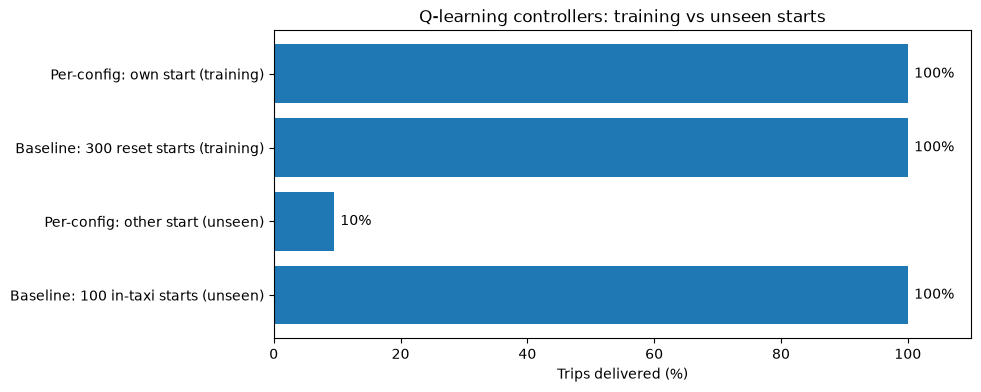

In [84]:
plt.figure(figsize=(9, 4))
delivered_pct = evaluation_df["delivered"] / evaluation_df["trips"] * 100
plt.barh(evaluation_df["test"], delivered_pct)
for i, v in enumerate(delivered_pct):
    plt.text(v + 1, i, f"{v:.0f}%", va="center")
plt.xlim(0, 110)
plt.xlabel("Trips delivered (%)")
plt.title("Q-learning controllers: training vs unseen starts")
plt.gca().invert_yaxis()
plt.show()

### Do the two approaches choose the same actions?

For every configuration, compare the per-configuration table's best action with the baseline table's best action in the same state. When they differ, check whether both are on a shortest route (for example south-then-west vs west-then-south).

In [85]:
def is_optimal_action(state, action):
    prob, next_state, reward, terminated = u.P[state][action][0]
    if terminated:
        return True
    if next_state == state:          # bumped into a wall or illegal pickup/drop-off: no progress
        return False
    return shortest_path_length(next_state) == shortest[state] - 1

same, both_optimal = 0, 0
for s in configurations:
    config = tuple(int(v) for v in u.decode(s))
    a_config = choose_best_action(q_tables[config], s)
    a_baseline = choose_best_action(Q, s)
    same += a_config == a_baseline
    both_optimal += is_optimal_action(s, a_config) and is_optimal_action(s, a_baseline)

print(f"Same best action        : {same} / {len(configurations)}")
print(f"Both actions optimal    : {both_optimal} / {len(configurations)}")
print(f"Training time  baseline : {baseline_time:.1f} s ({num_episodes} episodes)")
print(f"Training time  per-config: {per_config_time:.1f} s ({len(q_tables) * episodes_per_config} episodes)")

Same best action        : 324 / 400
Both actions optimal    : 400 / 400
Training time  baseline : 8.5 s (10000 episodes)
Training time  per-config: 170.2 s (120000 episodes)


## 5. Dataset for Part 2 (404 rows)

One row per reachable configuration: `(taxi_row, taxi_col, pass_idx, dest_idx) -> best_action`. The best action comes from **that configuration's own Q-table** (from the per-configuration runs).

The 4 finished states were not trained because the episode has already ended there.

In [86]:
rows = []
for s in reachable_states:
    taxi_row, taxi_col, pass_idx, dest_idx = (int(v) for v in u.decode(s))
    if s in finished_states:
        best_action = 0                                       # no decision to learn: label by convention
    else:
        best_action = choose_best_action(q_tables[(taxi_row, taxi_col, pass_idx, dest_idx)], s)
    rows.append({"state": s, "taxi_row": taxi_row, "taxi_col": taxi_col,
                 "pass_idx": pass_idx, "dest_idx": dest_idx, "best_action": best_action})

dataset_df = pd.DataFrame(rows).set_index("state")

print(dataset_df.shape)
print("How many times each action is the best action:")
print(dataset_df["best_action"].value_counts().sort_index())
print("Finished states (label 0 by convention):")
print(dataset_df.loc[finished_states])

(404, 5)
How many times each action is the best action:
best_action
0    114
1    145
2     56
3     73
4     12
5      4
Name: count, dtype: int64
Finished states (label 0 by convention):
       taxi_row  taxi_col  pass_idx  dest_idx  best_action
state                                                     
0             0         0         0         0            0
85            0         4         1         1            0
410           4         0         2         2            0
475           4         3         3         3            0


In [87]:
# check: driving with the dataset's labels delivers every trip by the shortest route
label_steps = []
for s in start_states:
    env.reset()
    u.s = s
    state = s
    for step in range(1, 201):
        state, reward, terminated, truncated, info = env.step(int(dataset_df.loc[state, "best_action"]))
        if terminated:
            break
    label_steps.append((terminated, step == shortest[s]))

print("Delivered       :", sum(t for t, _ in label_steps), "/", len(start_states))
print("Shortest route  :", sum(o for _, o in label_steps), "/", len(start_states))

Delivered       : 300 / 300
Shortest route  : 300 / 300


In [88]:
dataset_df.to_csv("taxi_dataset_404.csv")
print("Saved taxi_dataset_404.csv")

Saved taxi_dataset_404.csv
